# Lab 3.6 — Can two attention heads fit in one projection?

Compute two independent attention maps the slow way, then reproduce them with packed tensors. Both implementations use the same random parameters.

## Split the feature axis

With width eight and two heads, each query has four features per head. The softmax runs over source positions separately for each head. Predict the shapes before reading the output.

In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from torch import nn
from llm_lab.experiments import record, show

torch.manual_seed(34)
torch.set_num_threads(1)

from llm_lab.gpt import Attention
head = Attention(8, 2)
x = torch.randn(1, 5, 8)
maps, parts = [], []
q, k, v = head.c_attn(x).chunk(3, -1)
for qi, ki, vi in zip(q.chunk(2,-1), k.chunk(2,-1), v.chunk(2,-1)):
    scores = qi @ ki.transpose(-1,-2) / 2
    weights = scores.masked_fill(torch.ones(5,5).bool().triu(1), -torch.inf).softmax(-1)
    maps.append(weights.detach()[0])
    parts.append(weights @ vi)
manual = head.c_proj(torch.cat(parts, -1))
torch.testing.assert_close(manual, head(x))
print("Head maps, joined output:", maps[0].shape, manual.shape)

Head maps, joined output: torch.Size([5, 5]) torch.Size([1, 5, 8])


## Remove one head before mixing

The output projection can send each head’s features to every residual coordinate. Predict whether zeroing the first head can change the last four output coordinates. These random heads let us test the algebra without attributing semantic roles to them.

Final position, change across output features: tensor([-0.1299,  0.1175,  0.1636,  0.0808, -0.0162, -0.2386,  0.0039, -0.0449])
Out[2]: PosixPath('checkpoints/lab36/head_trace.npz')


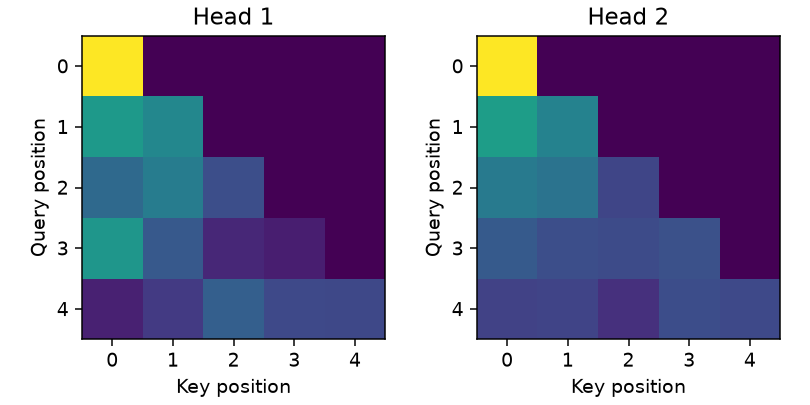

In [2]:
lesion = head.c_proj(torch.cat([torch.zeros_like(parts[0]), parts[1]], -1))
delta = (manual-lesion)[0,-1].detach()
print("Final position, change across output features:", delta)
fig, axes = plt.subplots(1,2,figsize=(6,3))
for i, ax in enumerate(axes):
    ax.imshow(maps[i], vmin=0, vmax=1)
    ax.set(title=f"Head {i+1}", xlabel="Key position", ylabel="Query position")
show(36, "two_heads")
record(36, "head_trace", maps=torch.stack(maps), delta=delta)

## Reading the result

The loop gives each head its own five-by-five attention map. Packing the heads introduces a head axis so PyTorch can compute both maps in one operation. Concatenating the two value mixtures restores width eight. The final projection explains why removing four intermediate features changed all eight output coordinates in this run.

What result would you predict if the output projection were the identity matrix?